In [7]:
import pandas as pd

import numpy as np

from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error

from sklearn.metrics import mean_squared_error

from lightgbm import LGBMRegressor

import matplotlib.pyplot as plt

In [8]:
!pip install lightgbm

In [9]:
data = pd.read_csv(
    'C:/Users/pilli/Downloads/M5_Thesis_Project/data/processed/feature_engineered_data.csv'
)

data.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,...,snap_WI,sell_price,week,lag_7,lag_28,rolling_mean_7,rolling_mean_28,is_weekend,month_start,month_end
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1178,0,2014-04-20,11412,...,0,8.26,16,0.0,0.0,0.571429,0.392857,0,0,0
1,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1234,2,2014-06-15,11420,...,1,8.26,24,0.0,1.0,0.428571,0.428571,0,0,0
2,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_828,1,2013-05-05,11315,...,1,3.97,18,0.0,0.0,0.142857,0.142857,0,0,0
3,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1178,0,2014-04-20,11412,...,0,3.97,16,0.0,0.0,0.142857,0.142857,0,0,0
4,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1234,0,2014-06-15,11420,...,1,3.97,24,2.0,0.0,0.571429,0.500000,0,0,0


In [10]:
data = data.dropna()

print(data.shape)

(1610, 30)


In [11]:
print(data.columns)

Index(['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id', 'd',
       'sales', 'date', 'wm_yr_wk', 'weekday', 'wday', 'month', 'year',
       'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2',
       'snap_CA', 'snap_TX', 'snap_WI', 'sell_price', 'week', 'lag_7',
       'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'is_weekend',
       'month_start', 'month_end'],
      dtype='object')


In [12]:
features = [
    'lag_7',
    'lag_28',
    'rolling_mean_7',
    'rolling_mean_28',
    'sell_price',
    'month',
    'week',
    'weekday'
]

target = 'sales'

In [13]:
X = data[features]

y = data[target]

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=False
)

print(X_train.shape)

print(X_test.shape)

(1288, 8)
(322, 8)


In [15]:
shuffle=False

In [16]:
model = LGBMRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

model.fit(
    X_train,
    y_train
)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000461 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 361
[LightGBM] [Info] Number of data points in the train set: 1288, number of used features: 7
[LightGBM] [Info] Start training from score 1.278727
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -i

C:\Users\pilli\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\pilli\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\pilli\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pilli\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\pilli\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

LGBMRegressor(max_depth=6, random_state=42)

In [17]:
predictions = model.predict(X_test)

print(predictions[:10])

[ 1.24879711  2.05526215  1.80925244 -0.22655531 -1.56539659 -1.40660182
  0.59758806  1.01379711  0.64942941  0.58376536]


In [35]:
lightgbm_metrics = pd.DataFrame({
    'Model': ['LightGBM'],
    'MAE': [mae],
    'RMSE': [rmse]
})

lightgbm_metrics.to_csv(
    'C:/Users/pilli/Downloads/M5_Thesis_Project/results/metrics/lightgbm_metrics.csv',
    index=False
)

lightgbm_metrics

,Model,MAE,RMSE
0,LightGBM,0.559155,1.126784


In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
import os

BASE_PATH = r'C:\Users\pilli\Downloads\M5_Thesis_Project'

lgbm_preds = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'lgbm_predictions_v4.csv'))

corrected_mae = mean_absolute_error(lgbm_preds['sales'], lgbm_preds['lgbm_pred'])
corrected_rmse = np.sqrt(mean_squared_error(lgbm_preds['sales'], lgbm_preds['lgbm_pred']))

print("="*60)
print("CORRECTED LIGHTGBM METRICS (SKU-LEVEL)")
print("="*60)
print(f"LightGBM MAE:  {corrected_mae:.4f}")
print(f"LightGBM RMSE: {corrected_rmse:.4f}")

results_df = pd.DataFrame({
    'Model': ['LightGBM'],
    'MAE': [f"{corrected_mae:.4f}"],
    'RMSE': [f"{corrected_rmse:.4f}"]
})

print("\nTABLE FOR THESIS:")
print(results_df.to_string(index=False))

CORRECTED LIGHTGBM METRICS (SKU-LEVEL)
LightGBM MAE:  0.9839
LightGBM RMSE: 2.2799

TABLE FOR THESIS:
   Model    MAE   RMSE
LightGBM 0.9839 2.2799


✅ Saved: lgbm_forecast_vs_actual_CORRECTED.png


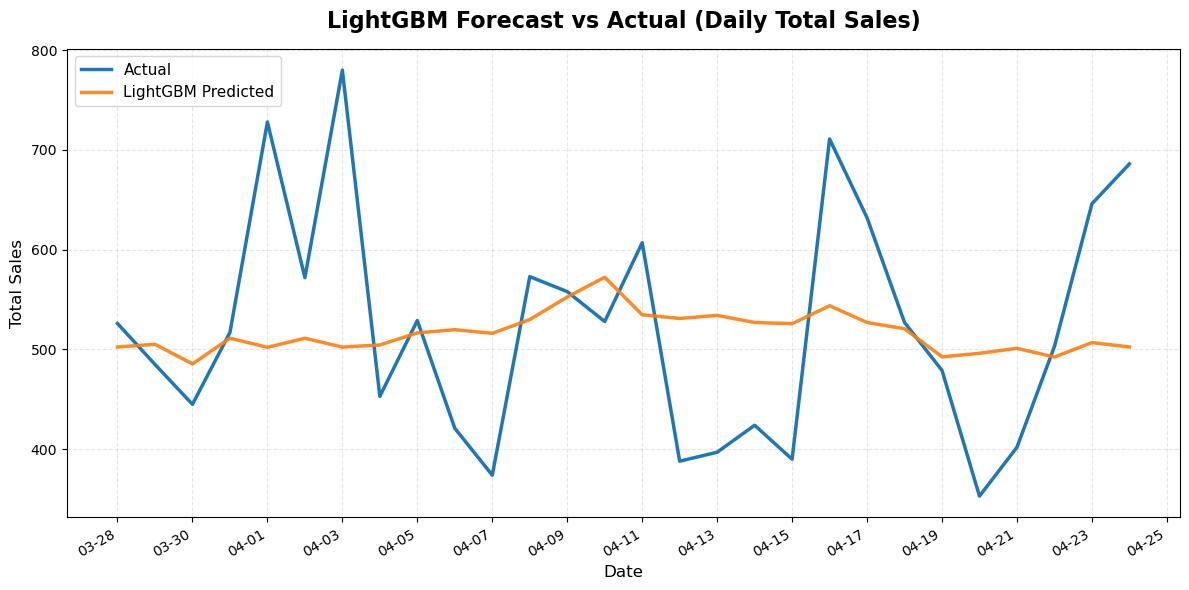

In [5]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

lgbm_preds = pd.read_csv(os.path.join(BASE_PATH, 'results', 'predictions', 'lgbm_predictions_v4.csv'))
lgbm_preds['date'] = pd.to_datetime(lgbm_preds['date'])

daily_actual = lgbm_preds.groupby('date')['sales'].sum()
daily_pred = lgbm_preds.groupby('date')['lgbm_pred'].sum()

plt.figure(figsize=(12, 6))
plt.plot(daily_actual.index, daily_actual.values, label='Actual', linewidth=2.5, color='#1f77b4')
plt.plot(daily_pred.index, daily_pred.values, label='LightGBM Predicted', linewidth=2.5, color='#ff7f0e', alpha=0.9)

plt.title('LightGBM Forecast vs Actual (Daily Total Sales)', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Total Sales', fontsize=12)

plt.xticks(rotation=30, ha='right')
plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=2))  # Show every 2nd day
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))  # Show month-day only

plt.legend(fontsize=11, loc='upper left')
plt.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()

plt.savefig(os.path.join(BASE_PATH, 'results', 'figures', 'lgbm_forecast_vs_actual_CORRECTED.png'), dpi=300, bbox_inches='tight')
print("✅ Saved: lgbm_forecast_vs_actual_CORRECTED.png")
plt.show()